# Sports league scheduling

The Four Coasts League is a fictional league of eight clubs. Every club hosts every other club once
per season, so the league has 56 matches to fit into a calendar of rounds. The question is **which
match is played in which round**, so that no club plays twice in a round, no club sits at home or on
the road for too long, the derbies land on weekends, and the clubs travel as little as possible.

In this notebook you will:

1. describe a league as Python objects,
2. solve it and print the fixture list and each club's home and away pattern,
3. check the result yourself, without trusting the solver's score,
4. turn the derby preference off, and then into a hard rule,
5. add rounds to the calendar, and see what the travel score does and does not measure,
6. restart the search from an existing fixture list.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from optimaru import sports_league_scheduling as sl
from optimaru.sports_league_scheduling.constraints import ClassicMatches, get_constraints
from optimaru.sports_league_scheduling.models import LeagueScheduleModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the league

| Object | What it holds |
| --- | --- |
| `Team` | an id and a name. Matches refer to teams by list position |
| `Round` | `index`, the number that defines which rounds are adjacent, and `weekend_or_holiday` |
| `Match` | home team, away team, and `classic_match` for a derby |
| `distance_to_team` | a matrix of kilometers from each team to each other team |

`Match.round` is the one decision, a position in the `rounds` list. The clubs sit in four coastal
regions of an invented country, two per region, and the two clubs of a region make a derby. Rounds
alternate between midweek and weekend. There are 14 rounds for 14 match days per club, so with this
calendar every club plays in every round.

In [2]:
TEAMS = ["Port Alder", "Ashford Mills", "Brackwater", "Cinder Bay",
         "Dunmere", "Eastholm", "Fallow Ridge", "Greywick"]
CODES = ["PAL", "ASH", "BRK", "CIN", "DUN", "EAS", "FAL", "GRY"]
REGIONS = ["North West", "South West", "North East", "South East"]
DERBIES = [(0, 1), (2, 3), (4, 5), (6, 7)]

rng = np.random.default_rng(5)
centers = [(120, 140), (160, 560), (620, 120), (640, 600)]
positions = np.array([(x + rng.normal(0, 45), y + rng.normal(0, 45)) for x, y in centers for _ in range(2)])
DISTANCE_KM = np.rint(np.linalg.norm(positions[:, None] - positions[None], axis=2)).astype(int).tolist()


def make_schedule(round_count=14):
    """A fresh, unsolved league. Solvers work in place, so each experiment gets its own."""
    teams = [sl.Team(code, name) for code, name in zip(CODES, TEAMS)]
    rounds = [sl.Round(k, weekend_or_holiday=k % 2 == 1) for k in range(round_count)]
    derbies = {frozenset(pair) for pair in DERBIES}
    matches = [
        sl.Match(f"{CODES[home]}-{CODES[away]}", home, away, classic_match=frozenset((home, away)) in derbies)
        for home in range(len(TEAMS)) for away in range(len(TEAMS)) if home != away
    ]
    return sl.LeagueSchedule(teams, rounds, matches, DISTANCE_KM)


schedule = make_schedule()
print(f"{schedule.team_count()} teams, {schedule.round_count()} rounds, {schedule.match_count()} matches, "
      f"{sum(m.classic_match for m in schedule.matches)} derbies, "
      f"{sum(r.weekend_or_holiday for r in schedule.rounds)} weekend rounds")

8 teams, 14 rounds, 56 matches, 8 derbies, 7 weekend rounds


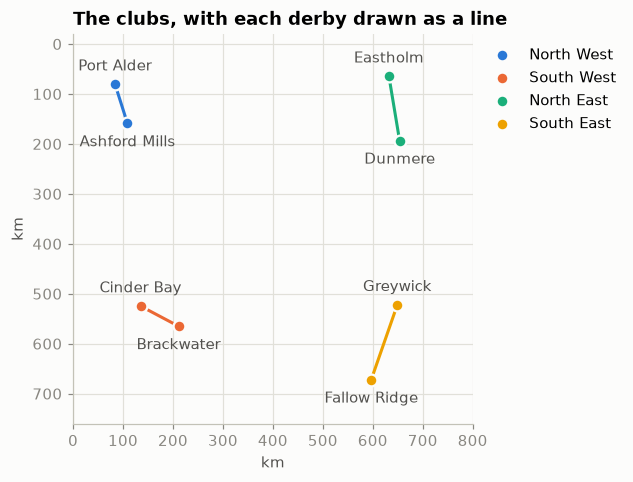

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for region, name in enumerate(REGIONS):
    members = positions[region * 2:region * 2 + 2]
    ax.plot(*members.T, color=COLORS[region], linewidth=2, zorder=1)
    ax.scatter(*members.T, s=60, color=COLORS[region], edgecolor="#fcfcfb", linewidth=1.5, zorder=2, label=name)
for k, (x, y) in enumerate(positions):
    above = y < positions[k + 1 - 2 * (k % 2), 1]  # the upper club of a pair is labelled above its dot
    ax.annotate(TEAMS[k], (x, y), xytext=(0, 9 if above else -15), textcoords="offset points",
                ha="center", color=INK)
ax.set(title="The clubs, with each derby drawn as a line", xlabel="km", ylabel="km",
       xlim=(0, 800), ylim=(760, -20))
ax.set_aspect("equal")
ax.grid(True)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

`sl.solve` works in place: `round` on each match and the score are written back. The score has two
levels, compared in order:

- **hard**: minus the number of violations, where `0` means the fixture list is feasible. A club may
  not play twice in a round, may not play four or more home or away rounds in a row, and may not meet
  the same opponent in two consecutive rounds.
- **soft**: minus the kilometers traveled, and minus 1000 per derby outside a weekend or holiday.

Feasibility is not guaranteed on a short budget. With exactly as many rounds as match days the calendar
has no slack, so check `is_feasible()`.

In [4]:
TIME_LIMIT = 2
SEED = 1

sl.solve(schedule, time_limit_seconds=TIME_LIMIT, random_seed=SEED)

print("feasible:", schedule.score.is_feasible())
print("score   :", schedule.score.hard, "/", schedule.score.soft)
breakdown = sl.compute_breakdown(schedule)
print("derbies outside a weekend:", breakdown.classic_match_count)
print(f"kilometers in the score  : {breakdown.soft_total() - 1000 * breakdown.classic_match_count}")

feasible: True
score   : 0 / -38044.0
derbies outside a weekend: 1
kilometers in the score  : 37044


### The fixture list

This is the page a league office would publish, one row per round. Derbies are highlighted, and weekend
rounds are shaded.

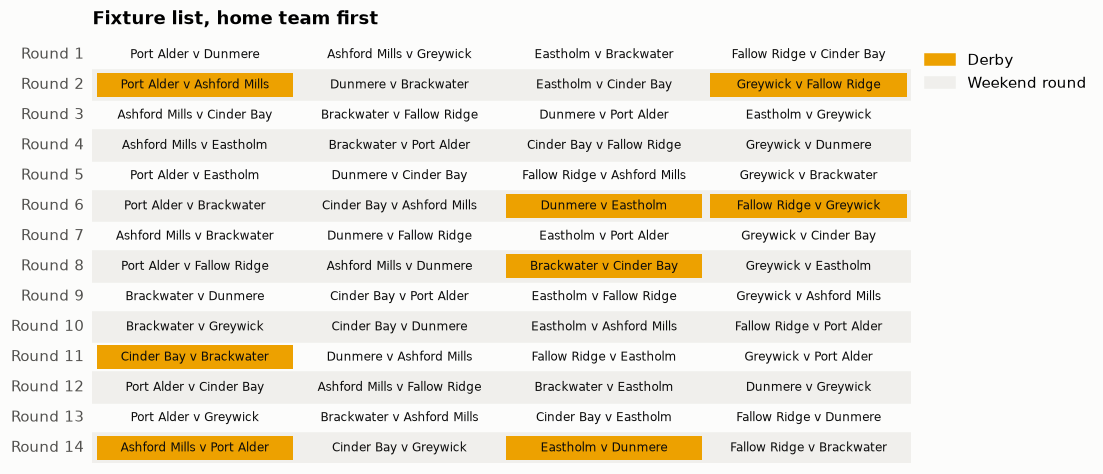

In [5]:
def round_of(schedule, match):
    return schedule.rounds[match.round].index


def draw_fixtures(schedule):
    by_round = {r.index: [] for r in schedule.rounds}
    for match in schedule.matches:
        by_round[round_of(schedule, match)].append(match)

    fig, ax = plt.subplots(figsize=(9.6, 5))
    for row, r in enumerate(schedule.rounds):
        if r.weekend_or_holiday:
            ax.axhspan(row - 0.5, row + 0.5, color="#f0efec", zorder=0)
        ax.text(-0.04, row, f"Round {r.index + 1}", ha="right", va="center", color=INK)
        for col, match in enumerate(sorted(by_round[r.index], key=lambda m: m.home_team)):
            if match.classic_match:
                ax.barh(row, 0.96, left=col + 0.02, height=0.8, color=COLORS[3], zorder=1)
            ax.text(col + 0.5, row, f"{TEAMS[match.home_team]} v {TEAMS[match.away_team]}",
                    ha="center", va="center", fontsize=8, color="#0b0b0b", zorder=2)
    ax.set_xlim(0, 4)
    ax.set_ylim(len(schedule.rounds) - 0.5, -0.5)
    ax.axis("off")
    ax.set_title("Fixture list, home team first", pad=10)
    ax.legend(handles=[Patch(color=COLORS[3], label="Derby"), Patch(color="#f0efec", label="Weekend round")],
              loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()


draw_fixtures(schedule)

### Home and away patterns

The same matches from each club's side: one row per club, one column per round, and the opponent's code
in the cell. Long runs of one color are what supporters and travel budgets feel. Empty cells would be
byes, and this calendar has none.

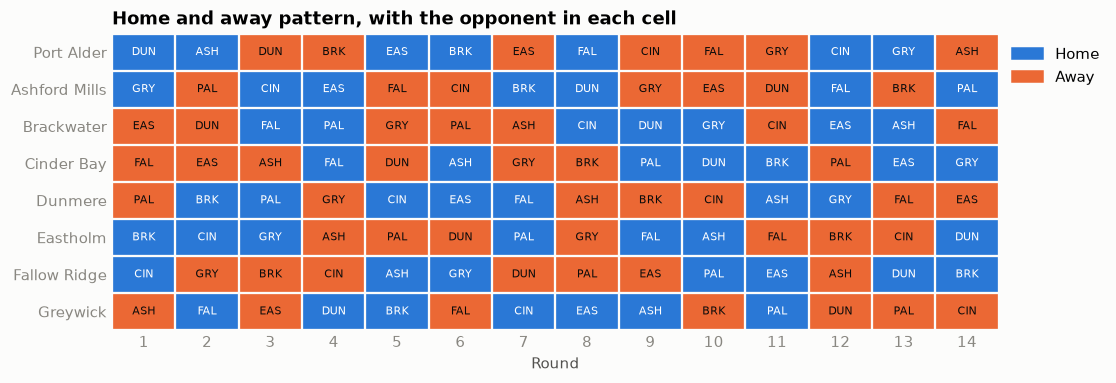

In [6]:
def pattern(schedule):
    """Matrix per team and round: 1 home, 2 away, 0 no match. Plus the opponent of each cell."""
    index = {r.index: k for k, r in enumerate(schedule.rounds)}
    grid = np.zeros((schedule.team_count(), schedule.round_count()), dtype=int)
    opponent = {}
    for match in schedule.matches:
        col = index[round_of(schedule, match)]
        grid[match.home_team, col], grid[match.away_team, col] = 1, 2
        opponent[match.home_team, col], opponent[match.away_team, col] = match.away_team, match.home_team
    return grid, opponent


def longest_run(row, value):
    best = run = 0
    for cell in row:
        run = run + 1 if cell == value else 0
        best = max(best, run)
    return best


grid, opponent = pattern(schedule)
fig, ax = plt.subplots(figsize=(10.4, 3.5))
ax.imshow(grid, cmap=ListedColormap(["#f0efec", COLORS[0], COLORS[1]]), vmin=0, vmax=2, aspect="auto")
for (team, col), other in opponent.items():
    ax.text(col, team, CODES[other], ha="center", va="center", fontsize=7.5,
            color="white" if grid[team, col] == 1 else "#0b0b0b")
ax.set_xticks(np.arange(grid.shape[1]), np.arange(grid.shape[1]) + 1)
ax.set_yticks(range(len(TEAMS)), TEAMS)
ax.set_xticks(np.arange(grid.shape[1] + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(TEAMS) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="#fcfcfb", linewidth=1.5)
ax.tick_params(which="both", length=0)
ax.spines[:].set_visible(False)
ax.set(title="Home and away pattern, with the opponent in each cell", xlabel="Round")
ax.legend(handles=[Patch(color=COLORS[0], label="Home"), Patch(color=COLORS[1], label="Away")],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The solver writes only `round` on each match, so all the rules can be recomputed from there. The travel
check walks each club's season from its home ground through every venue in round order, and back home.

double-booked team-rounds   0
longest home run            3
longest away run            3
return fixture next round   0

kilometers recounted 37044, kilometers in the score 37044
every match has a round: True


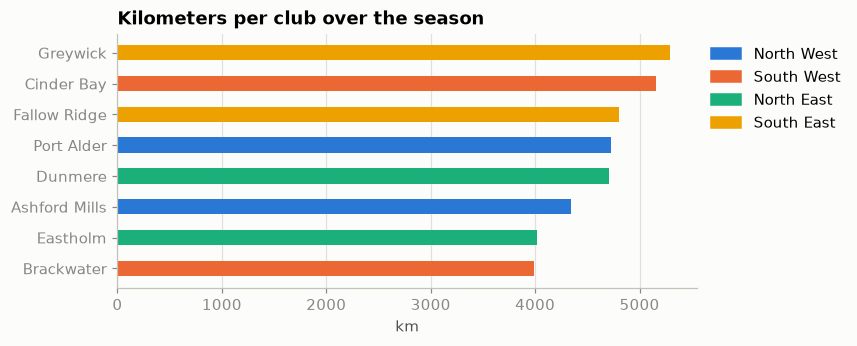

In [7]:
def true_travel(schedule):
    """Kilometers per team: home, then each venue in round order, then home."""
    km = []
    for team in range(schedule.team_count()):
        venues = sorted((round_of(schedule, m), m.home_team) for m in schedule.matches
                        if team in (m.home_team, m.away_team))
        here, total = team, 0
        for _, venue in venues:
            total += DISTANCE_KM[here][venue]
            here = venue
        km.append(total + DISTANCE_KM[here][team])
    return km


def scored_travel(schedule):
    b = sl.compute_breakdown(schedule)
    return b.soft_total() - 1000 * b.classic_match_count


def count_violations(schedule):
    grid, _ = pattern(schedule)
    per_slot = {}
    for match in schedule.matches:
        for team in (match.home_team, match.away_team):
            key = team, round_of(schedule, match)
            per_slot[key] = per_slot.get(key, 0) + 1
    rounds_of = {(m.home_team, m.away_team): round_of(schedule, m) for m in schedule.matches}
    return {
        "double-booked team-rounds": sum(count > 1 for count in per_slot.values()),
        "longest home run": max(longest_run(row, 1) for row in grid),
        "longest away run": max(longest_run(row, 2) for row in grid),
        "return fixture next round": sum(abs(rounds_of[a, b] - rounds_of[b, a]) == 1
                                         for a, b in rounds_of if a < b),
    }


for rule, value in count_violations(schedule).items():
    print(f"{rule:28s}{value}")

travel = true_travel(schedule)
print(f"\nkilometers recounted {sum(travel)}, kilometers in the score {scored_travel(schedule)}")
print(f"every match has a round: {all(m.round >= 0 for m in schedule.matches)}")

fig, ax = plt.subplots(figsize=(6.8, 3))
order = np.argsort(travel)[::-1]
ax.barh([TEAMS[k] for k in order], [travel[k] for k in order], height=0.5,
        color=[COLORS[k // 2] for k in order])
ax.invert_yaxis()
ax.set(title="Kilometers per club over the season", xlabel="km")
ax.grid(True, axis="x")
ax.legend(handles=[Patch(color=COLORS[k], label=REGIONS[k]) for k in range(4)],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

The score minimizes total travel, not a fair share, so clubs far from the others carry more of it.

## 4. Change the rules

`list_constraints()` names the rules. `get_constraints()` returns the default list, and only what you pass
to `solve(constraints=...)` is scored. Leaving a rule out removes it, and swapping in a spec changes it.

In [8]:
print(sl.list_constraints())

['start_to_away_hop', 'away_to_end_hop', 'classic_matches', 'matches_on_same_day', 'consecutive_home_matches', 'consecutive_away_matches', 'repeat_match_on_next_day', 'home_to_away_hop', 'away_to_away_hop', 'away_to_home_hop']


Derbies pull against travel: placing one on a weekend can cost more kilometers than the 1000 points it
saves. To see how much that rule does, compare three versions on the same seeds: no derby rule at all,
the default, and a hard rule. `hard=True` with `weight=1` prices a midweek derby like any other hard
violation.

A hollow dot marks a run that ended with hard violations. These solves run for a second each, and every
added hard rule makes hard `0` harder to reach.

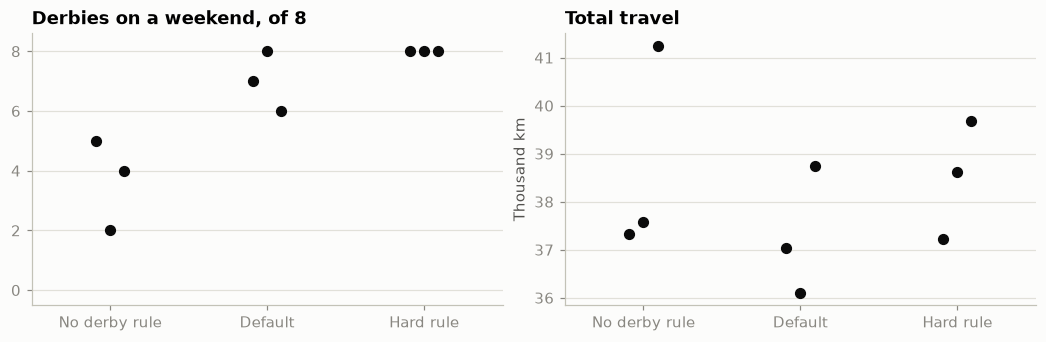

No derby rule  per seed (weekend derbies, km, no hard violation in the league rules): [(5, 37322, True), (2, 37585, True), (4, 41248, True)]
Default        per seed (weekend derbies, km, no hard violation in the league rules): [(7, 37044, True), (8, 36107, True), (6, 38737, True)]
Hard rule      per seed (weekend derbies, km, no hard violation in the league rules): [(8, 37226, True), (8, 38616, True), (8, 39676, True)]


In [9]:
without = [c for c in get_constraints() if c.name != "classic_matches"]
as_hard = without + [ClassicMatches(weight=1, hard=True)]
rule_sets = {"No derby rule": without, "Default": None, "Hard rule": as_hard}
seeds = (1, 2, 3)

outcomes = {}
for label, constraints in rule_sets.items():
    outcomes[label] = []
    for seed in seeds:
        run = make_schedule()
        sl.solve(run, time_limit_seconds=1, random_seed=seed, constraints=constraints)
        counts = count_violations(run)
        ok = counts["double-booked team-rounds"] == 0 and counts["return fixture next round"] == 0 \
            and max(counts["longest home run"], counts["longest away run"]) < 4
        weekend = sum(run.rounds[m.round].weekend_or_holiday for m in run.matches if m.classic_match)
        outcomes[label].append((weekend, sum(true_travel(run)), ok))

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3), layout="constrained")
for x, label in enumerate(outcomes):
    for k, (weekend, km, ok) in enumerate(outcomes[label]):
        style = dict(s=40, edgecolor="#0b0b0b", facecolor="#0b0b0b" if ok else "none")
        axes[0].scatter(x + (k - 1) * 0.09, weekend, **style)
        axes[1].scatter(x + (k - 1) * 0.09, km / 1000, **style)
axes[0].set(title="Derbies on a weekend, of 8", ylim=(-0.5, 8.6))
axes[1].set(title="Total travel", ylabel="Thousand km")
for ax in axes:
    ax.set_xticks(range(len(outcomes)), list(outcomes))
    ax.set_xlim(-0.5, len(outcomes) - 0.5)
    ax.grid(True, axis="y")
plt.show()

for label, runs in outcomes.items():
    print(f"{label:15s}per seed (weekend derbies, km, no hard violation in the league rules): {runs}")

The middle column shows that the default weight is a price, not a promise: a derby can still fall midweek
when the kilometers are worth more. Read the travel chart against the spread between seeds, because
some of what it shows is search noise.

## 5. Add rounds to the calendar

Each club owes 14 matches and plays at most one per round, so 13 rounds cannot work, whatever the search
does. Beyond 14, each extra round gives every club a bye to place.

Before reading the result, know how the score counts travel: a hop is only counted between matches in
**consecutive rounds**, or from the first round or to the last. Around a bye, nothing is counted, even
though the club still has to get from one venue to the next. So once a calendar has byes, the score
falls below the real distance, and the search can lower its score by placing byes rather than by
shortening trips. The chart shows both numbers, using `true_travel` from the check above.

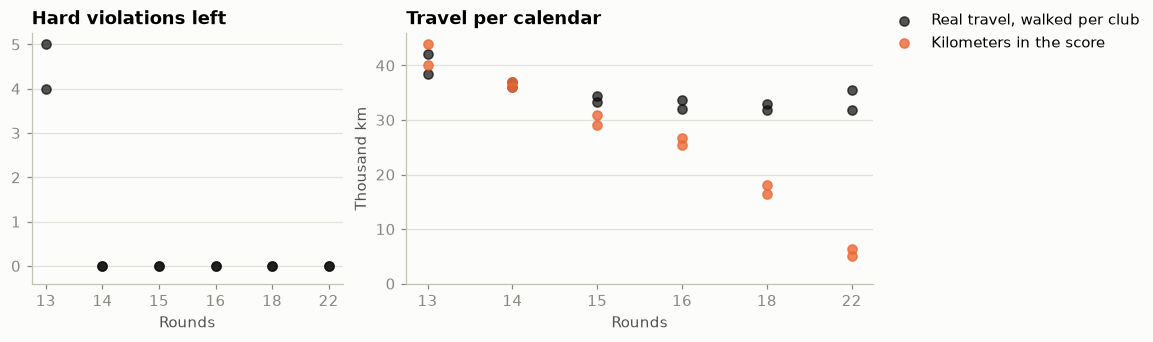

13 rounds: hard  -5, km in the score  40055, real km  38454
13 rounds: hard  -4, km in the score  43936, real km  42054
14 rounds: hard   0, km in the score  37044, real km  37044
14 rounds: hard   0, km in the score  36107, real km  36107
15 rounds: hard   0, km in the score  29065, real km  33298
15 rounds: hard   0, km in the score  30927, real km  34474
16 rounds: hard   0, km in the score  25428, real km  32010
16 rounds: hard   0, km in the score  26673, real km  33587
18 rounds: hard   0, km in the score  16445, real km  31793
18 rounds: hard   0, km in the score  18119, real km  32867
22 rounds: hard   0, km in the score   6314, real km  35413
22 rounds: hard   0, km in the score   5006, real km  31785


In [10]:
calendars = [13, 14, 15, 16, 18, 22]
sweep = []
for round_count in calendars:
    for seed in (1, 2):
        run = make_schedule(round_count)
        sl.solve(run, time_limit_seconds=1, random_seed=seed)
        sweep.append((round_count, run.score.hard, scored_travel(run), sum(true_travel(run))))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3), layout="constrained", width_ratios=[1, 1.5])
x_of = {count: k for k, count in enumerate(calendars)}
axes[0].scatter([x_of[r] for r, *_ in sweep], [-hard for _, hard, *_ in sweep], s=36, color="#0b0b0b", alpha=0.7)
axes[0].set(title="Hard violations left", ylim=(-0.4, None))
axes[0].yaxis.get_major_locator().set_params(integer=True)
axes[1].scatter([x_of[r] for r, *_ in sweep], [true / 1000 for *_, true in sweep], s=36, color="#0b0b0b",
                alpha=0.7, label="Real travel, walked per club")
axes[1].scatter([x_of[r] for r, *_ in sweep], [km / 1000 for _, _, km, _ in sweep], s=36, color=COLORS[1],
                alpha=0.8, label="Kilometers in the score")
axes[1].set(title="Travel per calendar", ylabel="Thousand km", ylim=(0, None))
for ax in axes:
    ax.set_xticks(range(len(calendars)), calendars)
    ax.set_xlabel("Rounds")
    ax.grid(True, axis="y")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside right upper")
plt.show()

for round_count, hard, scored, true in sweep:
    print(f"{round_count:2d} rounds: hard {hard:3d}, km in the score {scored:6d}, real km {true:6d}")

Use the score to compare calendars only when they have the same rounds and no byes. If your league has
byes, measure travel yourself, as `true_travel` does, and treat the score's kilometers as a partial count.

## 6. Restart from an existing fixture list

`with_initial_solution(problem, solution)` returns a copy of the problem whose search starts from a
solved `LeagueScheduleModel`, the pydantic mirror of the engine objects. `to_core()` turns it back into
what `solve` takes. Matches have no pinned flag in this use case, so a restart may move any of them.

**Give each round of restarts its own `random_seed`.** The same start with the same seed repeats the same
search. A same-seed round can still improve while its start differs from the round before, but once a
round finds nothing, it hands back its own start and every later round is the same search again.

On this instance a search tends to stall early, so more seconds on one seed do little, while a new seed
from the same start can move on. That is why these rounds are short. The right-hand chart shows feasible
solves from scratch with the same budget and other seeds, on the same axis. If the lines stay flat and
the dots reach higher, new seeds from scratch are the better use of your time.

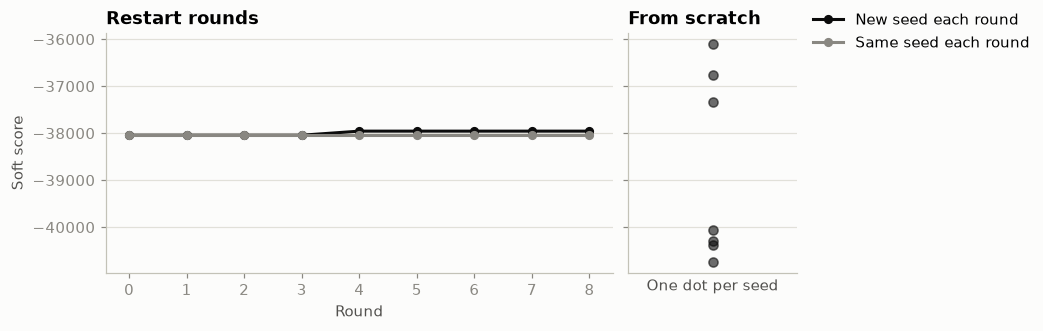

new seed    : [-38044.0, -38044.0, -38044.0, -38044.0, -37957.0, -37957.0, -37957.0, -37957.0, -37957.0]
same seed   : [-38044.0, -38044.0, -38044.0, -38044.0, -38044.0, -38044.0, -38044.0, -38044.0, -38044.0]
from scratch: [-36107.0, -40737.0, -37339.0, -40376.0, -40065.0, -40298.0, -36761.0]
matches moved by one more same-seed round: 0


In [11]:
problem = LeagueScheduleModel.from_core(make_schedule())
published = LeagueScheduleModel.from_core(schedule)


def rounds(seeds):
    current, history = published, [schedule.score.soft]
    for seed in seeds:
        restart = sl.with_initial_solution(problem, current).to_core()
        sl.solve(restart, time_limit_seconds=0.25, random_seed=seed)
        current = LeagueScheduleModel.from_core(restart)
        history.append(restart.score.soft)
    return current, history


_, new_seeds = rounds(range(2, 10))
settled, same_seed = rounds([SEED] * 8)

scratch = []
for seed in range(2, 10):
    fresh = make_schedule()
    sl.solve(fresh, time_limit_seconds=0.25, random_seed=seed)
    if fresh.score.is_feasible():
        scratch.append(fresh.score.soft)

fig, axes = plt.subplots(1, 2, figsize=(9.4, 2.9), sharey=True, width_ratios=[3, 1], layout="constrained")
axes[0].plot(new_seeds, color="#0b0b0b", linewidth=2, marker="o", markersize=5, label="New seed each round")
axes[0].plot(same_seed, color=MUTED, linewidth=2, marker="o", markersize=5, label="Same seed each round")
axes[0].set(title="Restart rounds", xlabel="Round", ylabel="Soft score")
axes[1].scatter(np.zeros(len(scratch)), scratch, s=36, color="#0b0b0b", alpha=0.6)
axes[1].set_xticks([])
axes[1].set(title="From scratch", xlabel="One dot per seed")
for ax in axes:
    ax.grid(True, axis="y")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right upper")
plt.show()

repeat = sl.with_initial_solution(problem, settled).to_core()
sl.solve(repeat, time_limit_seconds=0.25, random_seed=SEED)
changed = sum(a.round != b.round for a, b in zip(repeat.matches, settled.matches))

print("new seed    :", new_seeds)
print("same seed   :", same_seed)
print("from scratch:", scratch)
print("matches moved by one more same-seed round:", changed)

These scores are the best found in the time limit, not proven optima.

## Next steps

- `Round.index` may be sparse, for example `0, 1, 4`, and a gap counts as no round. `SolverConfig` holds the
  search options, such as `parallel_solver_count` for several starts.
- `use-cases/sports-league-scheduling/README.md` covers solver options and how to add moves and
  constraints in C++.
- For a single event with teams, days and courts, see `tournament-scheduling.ipynb`.